# MNIST Multiclass Classification: from softmax to honest probabilities

**The question:** MNIST is 70,000 handwritten digits (0 to 9), the "hello world" of machine learning. A small neural network can get about 98% of them right. That sounds finished, but there are better questions hiding behind the headline number. *How does a network turn pixels into a choice among ten digits? Do the small decisions we make (like how to scale the pixels, or how wide to make the network) really matter? How much data do we need? Can we trust the network when it says "I'm 99% sure"? And what happens when the digits are just slightly off-centre?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Softmax and cross-entropy from scratch
4. Audit the data
5. Hypotheses and why we chose each test
6. H1: does "amount of ink" separate digits?
7. H2: does standardising the inputs matter?
8. H3: does a wider network help?
9. H4: how much data do we need?
10. H5: can we trust the probabilities?
11. H6: what if the digits are off-centre?
12. H7: which digits get confused?
13. Takeaways
14. Limitations

**Run it:** `uv run jupyter lab DL/mnist-multiclass/mnist_multiclass.ipynb`, or *Run All* in any Jupyter. MNIST (about 12 MB) downloads itself on the first run. It uses a GPU if one is present and takes about 10 minutes on one.

## 1. 💡 The simple analogy

Imagine **ten judges, one for each digit, each holding up a score card** after looking at a picture. The "3 judge" holds up a high score if the picture looks like a 3, a low one otherwise, and so on for all ten. A neural network is a machine that learns how each judge should score.

- **Softmax** turns the ten raw score cards into **ten percentages that add up to 100%**: "70% sure it's a 3, 20% a 5, 10% a 8". The biggest percentage wins.
- **Cross-entropy** is the **"surprise" penalty** used for training: if the picture really was a 3 and the machine only gave it 1%, that's a huge surprise and a big penalty; if it gave 99%, the penalty is tiny. Training means adjusting the judges until the total surprise is small.
- **Calibration** asks a different question: when the machine says "90% sure", is it really right 90% of the time? A good judge is not just *right*, but *honestly confident*.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed and batch size keeps the notebook reproducible and avoids "magic numbers". With the seeds fixed (and the GPU set to deterministic mode), every model comes out the same each time you run it.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 42
BATCH = 128
N_BOOTSTRAP = 5_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Softmax and cross-entropy from scratch

*What:* the two ideas at the heart of every multi-class classifier, written out in a few lines of NumPy:

- **Softmax:** $p_k = \dfrac{e^{s_k}}{\sum_j e^{s_j}}$. Exponentiating makes every score positive, and dividing by the total makes the ten numbers add up to 1. (We subtract the largest score first, a trick that stops the exponentials from overflowing without changing the answer.)
- **Cross-entropy loss:** $L = -\log p_{\text{true class}}$, averaged over examples. It is the "surprise" penalty from the analogy: $-\log(0.99) \approx 0.01$ but $-\log(0.01) \approx 4.6$.

*Why write it by hand?* To see there is no magic. And we **check it against PyTorch** on a toy example (an `assert` stops the notebook if the two ever disagree).

In [2]:
def softmax(scores: np.ndarray) -> np.ndarray:
    """Turns raw class scores into probabilities that are positive and sum to 1.

    Subtracting the largest score first keeps the exponentials from overflowing.

    Args:
        scores: Array of shape (n_examples, n_classes).

    Returns:
        Probabilities of the same shape.
    """
    shifted = scores - scores.max(axis=1, keepdims=True)
    exps = np.exp(shifted)
    return exps / exps.sum(axis=1, keepdims=True)


def cross_entropy(probabilities: np.ndarray, labels: np.ndarray) -> float:
    """Average "surprise" at the true class: -log(probability given to the right answer).

    Args:
        probabilities: Predicted probabilities, shape (n_examples, n_classes).
        labels: True class indices.

    Returns:
        The mean cross-entropy loss.
    """
    return float(-np.log(probabilities[np.arange(len(labels)), labels] + 1e-12).mean())


scores = np.array([[2.0, 1.0, 0.1], [0.5, 2.5, 0.2]])
labels = np.array([0, 1])
mine = softmax(scores)
theirs = F.softmax(torch.tensor(scores), dim=1).numpy()
my_loss = cross_entropy(mine, labels)
their_loss = float(F.cross_entropy(torch.tensor(scores), torch.tensor(labels)))
print("Probabilities from my softmax:\n", mine.round(3))
print(f"Largest difference from PyTorch's softmax: {np.abs(mine - theirs).max():.1e}")
print(f"Cross-entropy: mine {my_loss:.6f}, PyTorch {their_loss:.6f}")
assert np.allclose(mine, theirs) and abs(my_loss - their_loss) < 1e-9

Probabilities from my softmax:
 [[0.659 0.242 0.099]
 [0.11  0.809 0.081]]
Largest difference from PyTorch's softmax: 1.4e-17
Cross-entropy: mine 0.314291, PyTorch 0.314291


## 4. Audit the data first

*What:* load MNIST and check what we have. *Why:* before training we should know the data's shape, how balanced the ten digits are, and what a clueless guess would score.

> **Problems in the legacy notebook this replaces:** it used `examples.next()` (an iterator method that no longer exists in current PyTorch), fed **raw pixel values** to the network with no standardisation, evaluated a **single run** of a single architecture (one hidden layer of 100 units) and reported one accuracy number with no baseline, no uncertainty and no look at *where* it fails.

Training images (60000, 1, 28, 28), test images (10000, 1, 28, 28)
Images per digit in training: min 5421, max 6742 (most common digit 1, least common 5)
Accuracy of always guessing the most common digit: 11.2%


Pixel mean 0.1307, standard deviation 0.3081; 81% of all pixels are exactly zero


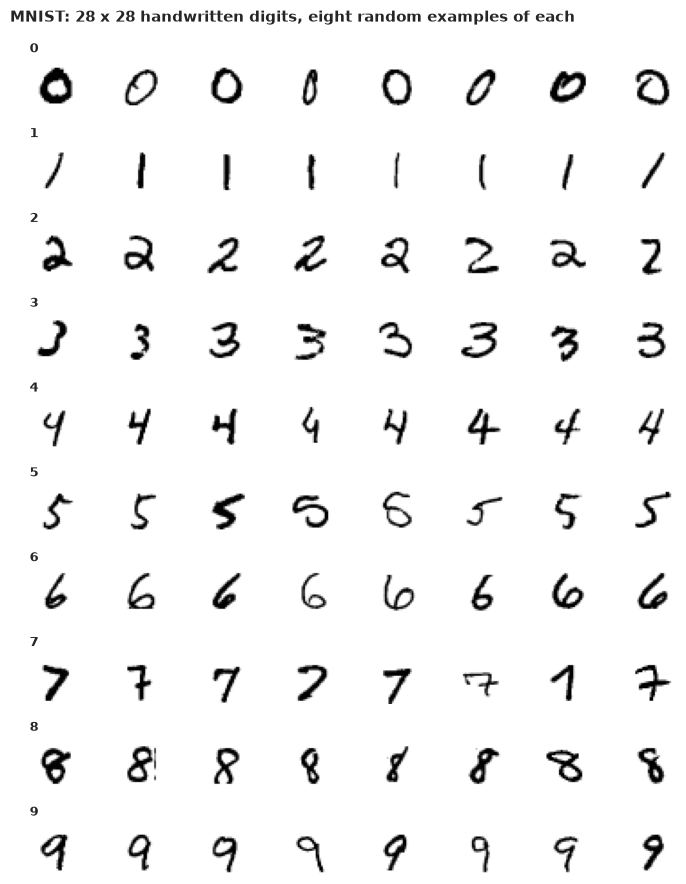

In [3]:
def load_mnist() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads MNIST as float images in [0, 1] with shape (N, 1, 28, 28).

    Returns:
        Training images and labels, then test images and labels.

    Raises:
        ValueError: If the dataset does not have the expected shape.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bars
        train = datasets.MNIST(DATA_DIR, train=True, download=True)
        test = datasets.MNIST(DATA_DIR, train=False, download=True)
    if tuple(train.data.shape) != (60_000, 28, 28) or tuple(test.data.shape) != (10_000, 28, 28):
        raise ValueError("Unexpected MNIST shape")
    return (
        train.data.unsqueeze(1).float() / 255,
        train.targets,
        test.data.unsqueeze(1).float() / 255,
        test.targets,
    )


raw_train, train_labels_cpu, raw_test, test_labels_cpu = load_mnist()
PIXEL_MEAN, PIXEL_STD = float(raw_train.mean()), float(raw_train.std())
counts = pd.Series(train_labels_cpu.numpy()).value_counts().sort_index()
print(f"Training images {tuple(raw_train.shape)}, test images {tuple(raw_test.shape)}")
print(
    f"Images per digit in training: min {counts.min()}, max {counts.max()} "
    f"(most common digit {counts.idxmax()}, least common {counts.idxmin()})"
)
print(f"Accuracy of always guessing the most common digit: {counts.max() / counts.sum():.1%}")
print(
    f"Pixel mean {PIXEL_MEAN:.4f}, standard deviation {PIXEL_STD:.4f}; "
    f"{(raw_train == 0).float().mean():.0%} of all pixels are exactly zero"
)

fig, axes = plt.subplots(10, 8, figsize=(7, 9))
rng = np.random.default_rng(SEED)
for digit in range(10):
    chosen = rng.choice(np.where(train_labels_cpu.numpy() == digit)[0], 8, replace=False)
    for col, index in enumerate(chosen):
        axes[digit, col].imshow(raw_train[index, 0], cmap="gray_r")
        axes[digit, col].axis("off")
        if col == 0:
            axes[digit, col].set_title(str(digit), loc="left", fontsize=9, fontweight="bold")
fig.suptitle(
    "MNIST: 28 x 28 handwritten digits, eight random examples of each",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_samples.png", dpi=130)
plt.show()

**How to read this.** There are **60,000 training and 10,000 test images**, each 28 x 28 grey-scale pixels. The digits are **almost balanced** (each has between about 5,400 and 6,700 training images, with **1 the most common and 5 the least**), so a model that always guessed the most common digit would score only about **11%**: that is the bar. Notice that **81% of all pixels are exactly zero** (blank background): most of every image is empty.

Also note the mean (0.13) and standard deviation (0.31) of the pixel values: they are the numbers we will use to **standardise** the inputs later.

## 5. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any result:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Does a crude "amount of ink" summary differ between digits? | Same distribution for all digits | At least one differs | Kruskal-Wallis with ε² |
| H2 | Does standardising the pixel values change accuracy? | No difference | A difference | 10 paired seeds; Wilcoxon signed-rank; bootstrap CI |
| H3 | Does a wider hidden layer help? | Same accuracy | Different | Exact McNemar test on the shared test images |
| H4 | Does a CNN beat an MLP when training data is scarce? | Same accuracy | Different | McNemar at 300 and at 60,000 training images |
| H5 | Are the predicted probabilities honest, and does temperature scaling fix them? | Calibration error unchanged | It falls | Expected calibration error with a bootstrap CI |
| H6 | Does a sideways shift hurt an MLP more than a CNN? | Same accuracy | The CNN is better | McNemar at 0, 2 and 4 pixels |
| H7 | Is accuracy the same for every digit? | Same accuracy | Some digits are harder | Chi-square test, Cramér's V, Wilson CIs |

**Why Kruskal-Wallis?** It is the rank-based version of one-way ANOVA: it compares the ten digits without assuming bell-shaped data. **ε²** is its effect size (about 0.01 small, 0.06 medium, 0.14 large). **Why a paired Wilcoxon (H2)?** Both versions start from the **same seed** (same initial weights, same batch order), so each seed gives a *pair* of results, and the Wilcoxon signed-rank test on the differences is the right non-parametric comparison. **Why McNemar (H3, H4, H6)?** Two classifiers are tested on the **same 10,000 images**, so the comparison is *paired*: only the images where **exactly one** model is right carry any information. The exact McNemar test asks whether, among those disagreements, each model is equally likely to be the right one. We add a bootstrap 95% CI for the accuracy difference by re-drawing the test images with replacement 5,000 times.

## 6. H1: does "amount of ink" separate digits?

*What:* a crude summary of every training image: its **average pixel brightness** (how much ink the digit uses). *Why:* a sanity check before any network. If even this one number differs between digits, there is signal in the raw pixels. **H₀:** all ten digits have the same distribution of ink.

Kruskal-Wallis on average ink: H = 20965, p = 0.0e+00, epsilon^2 = 0.35
Median ink (average pixel brightness), least to most:
1    0.073
7    0.111
4    0.118
9    0.119
5    0.125
6    0.134
3    0.139
8    0.147
2    0.147
0    0.172


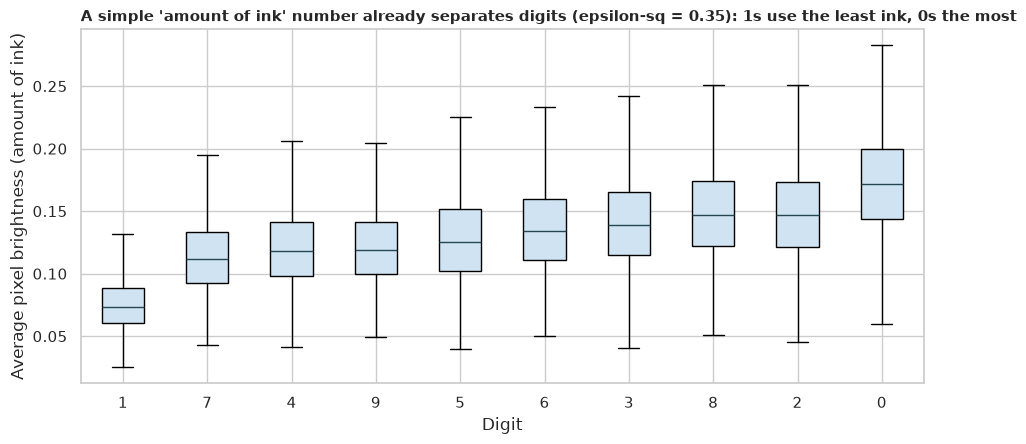

In [4]:
ink = raw_train.mean(dim=(1, 2, 3)).numpy()
digit_groups = [ink[train_labels_cpu.numpy() == d] for d in range(10)]
h_stat, p_ink = stats.kruskal(*digit_groups)
epsilon_sq = (h_stat - 10 + 1) / (len(ink) - 10)
medians = pd.Series([np.median(g) for g in digit_groups], index=range(10)).sort_values()
print(
    f"Kruskal-Wallis on average ink: H = {h_stat:.0f}, p = {fmt_p(p_ink)}, "
    f"epsilon^2 = {epsilon_sq:.2f}"
)
print("Median ink (average pixel brightness), least to most:")
print(medians.round(3).to_string())

fig, ax = plt.subplots(figsize=(9.5, 4.6))
order = list(medians.index)
ax.boxplot(
    [digit_groups[d] for d in order],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#cfe3f2"},
    medianprops={"color": NAVY},
)
ax.set_xticks(range(1, 11), [str(d) for d in order])
ax.set_xlabel("Digit")
ax.set_ylabel("Average pixel brightness (amount of ink)")
ax.set_title(
    f"A simple 'amount of ink' number already separates digits "
    f"(epsilon-sq = {epsilon_sq:.2f}): 1s use the least ink, 0s the most",
    loc="left",
    fontweight="bold",
    fontsize=10.5,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_ink_by_digit.png", dpi=150)
plt.show()

**How to read this.** The Kruskal-Wallis test gives H ≈ 21,000 and p ≈ 0 with **ε² ≈ 0.35, a large effect** (well past the 0.14 threshold), so **we reject H₀: even this one crude number separates the digits.** The median **1 uses the least ink (0.073)**, because it is a thin stroke, and **0 uses the most (0.172)**, with 2 and 8 close behind (0.147). The box plot also shows plenty of overlap (a fat 1 and a thin 0 look alike by this measure), which is why a real classifier needs the *shape* of the ink, not just the amount.

## The training toolkit

*What:* three families of model that we will compare, plus the function that trains them. **Softmax regression** has no hidden layer: each of the ten judges simply takes a weighted sum of the 784 pixels. An **MLP** (multi-layer perceptron) adds a hidden layer of units with a ReLU non-linearity in between. A **small CNN** (convolutional network) slides small 3 x 3 filters over the image (two convolution layers, 16 and 32 filters, with max-pooling). All use the **Adam** optimiser (learning rate 0.001), batches of 128, and the cross-entropy loss. The **seed** fixes both the starting weights and the order of the batches, so two runs with the same seed start from exactly the same place.

In [5]:
def prepare(images: torch.Tensor, standardise: bool = True) -> torch.Tensor:
    """Moves images to the device, optionally subtracting the mean and dividing by the spread.

    Args:
        images: Raw images in [0, 1].
        standardise: If True, use the training mean and standard deviation.

    Returns:
        The prepared tensor on the active device.
    """
    scaled = (images - PIXEL_MEAN) / PIXEL_STD if standardise else images
    return scaled.to(DEVICE)


train_std, test_std = prepare(raw_train), prepare(raw_test)
train_raw, test_raw = prepare(raw_train, False), prepare(raw_test, False)
train_labels, test_labels = train_labels_cpu.to(DEVICE), test_labels_cpu.to(DEVICE)


def build_model(kind: str, hidden: int = 100) -> nn.Module:
    """Builds a network.

    Args:
        kind: ``"softmax"`` (no hidden layer), ``"mlp"`` or ``"cnn"``.
        hidden: Hidden-layer width for the MLP.

    Returns:
        The untrained model on the active device.
    """
    if kind == "softmax":
        model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
    elif kind == "mlp":
        model = nn.Sequential(
            nn.Flatten(), nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10)
        )
    else:
        model = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(800, 10),
        )
    return model.to(DEVICE)


def train_model(
    kind: str, seed: int, x: torch.Tensor, y: torch.Tensor, epochs: int, hidden: int = 100
) -> nn.Module:
    """Trains a model with Adam on mini-batches.

    The seed fixes the starting weights and the batch order, so runs with the same seed start
    from the same point (a paired design).

    Args:
        kind: Model kind for :func:`build_model`.
        seed: Seed for initialisation and batch order.
        x: Training images.
        y: Training labels.
        epochs: Number of passes over the data.
        hidden: MLP hidden width.

    Returns:
        The trained model, in evaluation mode.
    """
    torch.manual_seed(seed)
    generator = torch.Generator(device="cpu").manual_seed(seed)
    model = build_model(kind, hidden)
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        order = torch.randperm(len(x), generator=generator).to(DEVICE)
        for start in range(0, len(x), BATCH):
            batch = order[start : start + BATCH]
            optimiser.zero_grad()
            F.cross_entropy(model(x[batch]), y[batch]).backward()
            optimiser.step()
    return model.eval()


@torch.no_grad()
def predict_logits(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    """Raw class scores for a set of images, computed in chunks.

    Args:
        model: A trained model.
        x: Images to score.

    Returns:
        Logits of shape (N, 10) on the active device.
    """
    return torch.cat([model(x[i : i + 2000]) for i in range(0, len(x), 2000)])


def accuracy(model: nn.Module, x: torch.Tensor, y: torch.Tensor) -> float:
    """Share of images the model classifies correctly.

    Args:
        model: A trained model.
        x: Images.
        y: True labels.

    Returns:
        Accuracy between 0 and 1.
    """
    return float((predict_logits(model, x).argmax(1) == y).float().mean())

## 7. H2: does standardising the inputs matter?

*What:* pixel values run from 0 to 1, with a mean of 0.13. **Standardising** means subtracting the mean and dividing by the standard deviation, so the inputs are centred on 0 with a spread of 1. Neural networks usually train better with centred inputs (the first layer's numbers start off in a sensible range). The legacy notebook skipped this. We test whether it matters: the **same MLP, from the same 10 seeds**, trained for 5 epochs on raw pixels and on standardised pixels, compared with a **paired Wilcoxon signed-rank test** (H₀: no difference) and a bootstrap 95% CI for the mean difference.

Mean test accuracy: raw 0.9680, standardised 0.9735
Paired difference (standardised minus raw): +0.0055 (95% bootstrap CI +0.0045 to +0.0064); Wilcoxon p = 0.0020; standardised won in 10 of 10 seeds


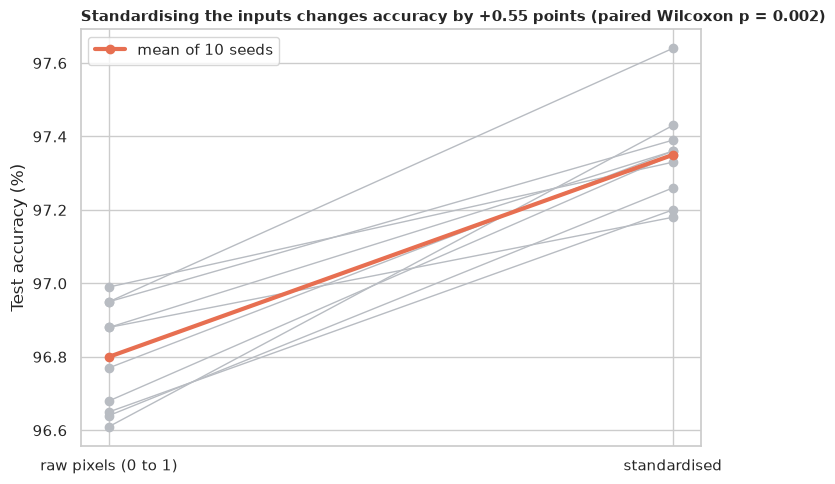

In [6]:
N_PAIRS = 10
EPOCHS = 5
norm_rows = []
for seed in range(N_PAIRS):
    raw_acc = accuracy(
        train_model("mlp", 100 + seed, train_raw, train_labels, EPOCHS), test_raw, test_labels
    )
    std_acc = accuracy(
        train_model("mlp", 100 + seed, train_std, train_labels, EPOCHS), test_std, test_labels
    )
    norm_rows.append({"seed": seed, "raw pixels": raw_acc, "standardised": std_acc})
norm = pd.DataFrame(norm_rows).set_index("seed")
diff = norm["standardised"] - norm["raw pixels"]
rng = np.random.default_rng(SEED)
boot = rng.choice(diff.to_numpy(), (N_BOOTSTRAP, len(diff))).mean(axis=1)
lo, hi = np.percentile(boot, [2.5, 97.5])
wilcoxon = stats.wilcoxon(diff)
print(
    f"Mean test accuracy: raw {norm['raw pixels'].mean():.4f}, standardised "
    f"{norm['standardised'].mean():.4f}"
)
print(
    f"Paired difference (standardised minus raw): {diff.mean():+.4f} "
    f"(95% bootstrap CI {lo:+.4f} to {hi:+.4f}); Wilcoxon p = {wilcoxon.pvalue:.4f}; "
    f"standardised won in {int((diff > 0).sum())} of {N_PAIRS} seeds"
)

fig, ax = plt.subplots(figsize=(7.5, 5))
for seed in norm.index:
    ax.plot(
        [0, 1],
        [norm.loc[seed, "raw pixels"] * 100, norm.loc[seed, "standardised"] * 100],
        color=GREY,
        marker="o",
        lw=1,
    )
ax.plot(
    [0, 1],
    [norm["raw pixels"].mean() * 100, norm["standardised"].mean() * 100],
    color=ORANGE,
    marker="o",
    lw=3,
    label="mean of 10 seeds",
)
ax.set_xticks([0, 1], ["raw pixels (0 to 1)", "standardised"])
ax.set_ylabel("Test accuracy (%)")
ax.legend()
ax.set_title(
    f"Standardising the inputs changes accuracy by {diff.mean() * 100:+.2f} points "
    f"(paired Wilcoxon p = {wilcoxon.pvalue:.3f})",
    loc="left",
    fontweight="bold",
    fontsize=10.5,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_standardising.png", dpi=150)
plt.show()

**How to read this.** Standardising the inputs raises mean test accuracy from **96.80% to 97.35%**, a paired difference of **+0.55 percentage points** (95% bootstrap CI +0.45 to +0.64), and **standardised won in all 10 of 10 seeds** (every grey line in the plot slopes upward). The Wilcoxon p-value is 0.002, which is the *smallest value that 10 pairs can ever give*, so it cannot get more significant with this design. **We reject H₀: the legacy notebook's decision to feed raw pixels cost about half a point of accuracy**, for free. (Half a point is small in absolute terms, but it is about 55 fewer mistakes per 10,000 images, and at the 98% level that is a fifth of all the errors.)

## 8. H3: does a wider network help?

## 8. H3: does a wider network help?

*What:* the legacy notebook used 100 hidden units, with no justification. We compare **10, 100 and 1,000 hidden units** (5 seeds each, 5 epochs, standardised inputs) and test each step with **McNemar's test** on the predictions of the first seed on the shared test images (the first model named is "A"). The table lists the parameter count, the mean test accuracy over seeds and the seed-to-seed standard deviation.

In [7]:
def mcnemar(correct_a: np.ndarray, correct_b: np.ndarray, rng: np.random.Generator) -> dict:
    """Exact McNemar test for two classifiers evaluated on the same test images.

    Only images where exactly one classifier is right carry information.

    Args:
        correct_a: Boolean vector, True where classifier A was right.
        correct_b: Boolean vector, True where classifier B was right.
        rng: Random generator for the bootstrap.

    Returns:
        A-only wins, B-only wins, accuracy difference (A minus B) with a bootstrap 95% CI,
        and the p-value.
    """
    a_only = int((correct_a & ~correct_b).sum())
    b_only = int((~correct_a & correct_b).sum())
    p_value = stats.binomtest(a_only, a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    delta = correct_a.astype(float) - correct_b.astype(float)
    boot = delta[rng.integers(0, len(delta), (N_BOOTSTRAP, len(delta)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {
        "A right, B wrong": a_only,
        "B right, A wrong": b_only,
        "accuracy difference": float(delta.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
        "p": float(p_value),
    }


truth = test_labels.cpu().numpy()
WIDTHS = [10, 100, 1000]
width_runs = {}
for width in WIDTHS:
    models = [
        train_model("mlp", 100 + seed, train_std, train_labels, EPOCHS, hidden=width)
        for seed in range(5)
    ]
    width_runs[width] = {
        "accuracy": [accuracy(m, test_std, test_labels) for m in models],
        "correct": predict_logits(models[0], test_std).argmax(1).cpu().numpy() == truth,
        "params": sum(p.numel() for p in models[0].parameters()),
    }
width_table = pd.DataFrame(
    {
        f"{w} hidden units": {
            "parameters": width_runs[w]["params"],
            "mean test accuracy": np.mean(width_runs[w]["accuracy"]),
            "seed std": np.std(width_runs[w]["accuracy"], ddof=1),
        }
        for w in WIDTHS
    }
).T
rng = np.random.default_rng(SEED)
width_tests = pd.DataFrame(
    {
        "100 vs 10 hidden units": mcnemar(
            width_runs[100]["correct"], width_runs[10]["correct"], rng
        ),
        "1000 vs 100 hidden units": mcnemar(
            width_runs[1000]["correct"], width_runs[100]["correct"], rng
        ),
    }
).T
display_width = width_table.copy()
display_width["parameters"] = display_width["parameters"].astype(int)
print(display_width.to_string(float_format=lambda v: f"{v:,.4f}" if v < 10 else f"{v:,.0f}"))
width_tests.style.format(
    {
        "accuracy difference": "{:+.4f}",
        "ci_low": "{:+.4f}",
        "ci_high": "{:+.4f}",
        "p": fmt_p,
        "A right, B wrong": "{:.0f}",
        "B right, A wrong": "{:.0f}",
    }
)

                   parameters  mean test accuracy  seed std
10 hidden units          7960              0.9252    0.0044
100 hidden units        79510              0.9734    0.0009
1000 hidden units      795010              0.9797    0.0013


,"A right, B wrong","B right, A wrong",accuracy difference,ci_low,ci_high,p
100 vs 10 hidden units,598,54,+0.0544,+0.0495,+0.0592,5.0e-117
1000 vs 100 hidden units,123,64,+0.0059,+0.0032,+0.0085,1.9e-05


**How to read this.**

- **From 10 to 100 hidden units: a big jump.** Mean accuracy rises from **92.5% to 97.3%** (+5.4 points; of the 652 test images on which the two disagree, the wider network is right in 598 and the narrow one in 54; McNemar p ≈ 5e-117). With only 10 hidden units the network is a bottleneck: it cannot keep enough information about the stroke shapes.
- **From 100 to 1,000 hidden units: a small gain for 10x the weights.** Accuracy rises to **98.0%** (+0.6 points, CI +0.32 to +0.85; 123 against 64 disagreements; p ≈ 2e-5). **We reject H₀ at both steps**, but notice the diminishing returns: ten times more parameters (80,000 to 795,000) buy only about six tenths of a percentage point.
- The seed-to-seed standard deviation is tiny (0.1 to 0.4 points), so these differences are not luck.

So width matters until it stops mattering. The legacy choice of 100 units was reasonable, but not obviously optimal.

## 9. H4: how much data do we need?

## 9. H4: how much data do we need?

*What:* a **learning curve**: train on 300, 1,200, 6,000, 30,000 and all 60,000 training images (each smaller set is a random sample, different for every seed) and see how accuracy grows. We compare three models: **softmax regression**, the **MLP** and the **small CNN**, with 3 seeds each. Small data sets are trained for more epochs so every model gets a fair number of update steps. *Why does this matter?* In practice labelled data is expensive, and a model's value often lies in how well it does with a *little* data. **H₀:** at a given training size, the CNN and the MLP are equally accurate (McNemar test on the first seed, at the smallest and the largest sizes).

In [8]:
SIZES = [300, 1_200, 6_000, 30_000, 60_000]
KINDS = {"softmax": "Softmax regression", "mlp": "MLP (100 hidden)", "cnn": "Small CNN"}
N_CURVE_SEEDS = 3
curve = {kind: {n: [] for n in SIZES} for kind in KINDS}
curve_correct = {}
for n in SIZES:
    epochs = int(np.clip(3_000 * BATCH // n, 5, 100))
    for kind in KINDS:
        for seed in range(N_CURVE_SEEDS):
            subset = torch.randperm(60_000, generator=torch.Generator().manual_seed(seed))[:n]
            subset = subset.to(DEVICE)
            model = train_model(kind, 100 + seed, train_std[subset], train_labels[subset], epochs)
            curve[kind][n].append(accuracy(model, test_std, test_labels))
            if seed == 0:
                curve_correct[(kind, n)] = (
                    predict_logits(model, test_std).argmax(1).cpu().numpy() == truth
                )

curve_table = pd.DataFrame({KINDS[k]: {n: np.mean(v) for n, v in curve[k].items()} for k in KINDS})
curve_table.index.name = "training images"
rng = np.random.default_rng(SEED)
curve_tests = pd.DataFrame(
    {
        f"{n:,} images": mcnemar(curve_correct[("cnn", n)], curve_correct[("mlp", n)], rng)
        for n in (SIZES[0], SIZES[-1])
    }
).T
curve_table.style.format("{:.4f}")

,Softmax regression,MLP (100 hidden),Small CNN
training images,,,
300,0.8409,0.8502,0.9120
1200,0.8780,0.9009,0.9558
6000,0.9018,0.9450,0.9783
30000,0.9221,0.9711,0.9863
60000,0.9244,0.9747,0.9882


In [9]:
curve_tests.style.format(
    {
        "accuracy difference": "{:+.4f}",
        "ci_low": "{:+.4f}",
        "ci_high": "{:+.4f}",
        "p": fmt_p,
        "A right, B wrong": "{:.0f}",
        "B right, A wrong": "{:.0f}",
    }
)

,"A right, B wrong","B right, A wrong",accuracy difference,ci_low,ci_high,p
300 images,776,141,+0.0635,+0.0578,+0.0692,6.7e-107
"60,000 images",159,52,+0.0107,+0.0079,+0.0134,8.4e-14


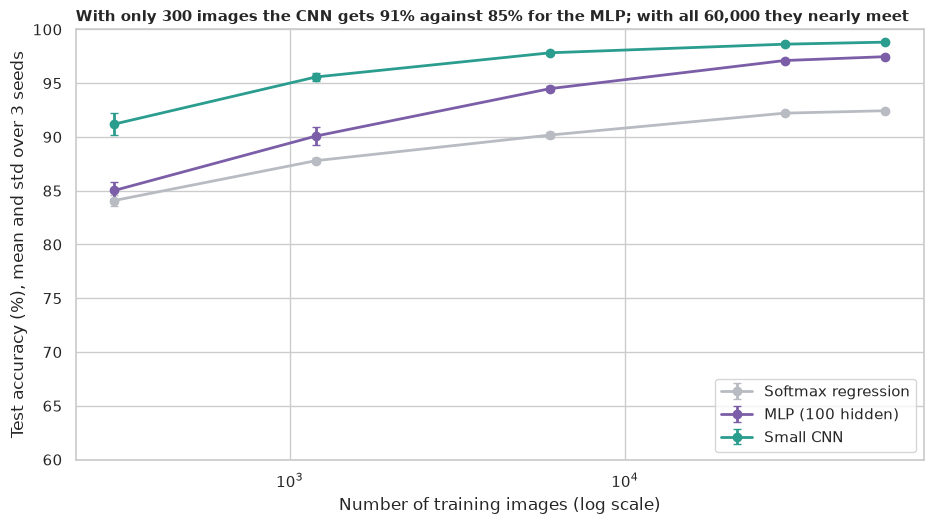

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
palette = {"softmax": GREY, "mlp": PURPLE, "cnn": TEAL}
for kind, label in KINDS.items():
    means = np.array([np.mean(curve[kind][n]) for n in SIZES]) * 100
    spread = np.array([np.std(curve[kind][n], ddof=1) for n in SIZES]) * 100
    ax.errorbar(
        SIZES, means, yerr=spread, marker="o", lw=2, capsize=3, color=palette[kind], label=label
    )
ax.set_xscale("log")
ax.set_xlabel("Number of training images (log scale)")
ax.set_ylabel("Test accuracy (%), mean and std over 3 seeds")
ax.legend(loc="lower right")
ax.set_ylim(60, 100)
first, last = curve_table.iloc[0], curve_table.iloc[-1]
ax.set_title(
    f"With only {SIZES[0]} images the CNN gets {first['Small CNN'] * 100:.0f}% against "
    f"{first['MLP (100 hidden)'] * 100:.0f}% for the MLP; with all 60,000 they nearly meet",
    loc="left",
    fontweight="bold",
    fontsize=10.5,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_learning_curve.png", dpi=150)
plt.show()

**How to read this.** (Test accuracy, mean of 3 seeds.)

| Training images | Softmax | MLP | Small CNN |
|---|---|---|---|
| 300 | 84.1% | 85.0% | **91.2%** |
| 1,200 | 87.8% | 90.1% | **95.6%** |
| 6,000 | 90.2% | 94.5% | **97.8%** |
| 30,000 | 92.2% | 97.1% | **98.6%** |
| 60,000 | 92.4% | 97.5% | **98.8%** |

- **The CNN wins at every size, and its edge is largest when data is scarce.** With **300 images** the CNN beats the MLP by **6.4 points** (McNemar: 776 against 141 disagreements, p ≈ 7e-107); with **all 60,000** the gap narrows to **1.1 points** (159 against 52; p ≈ 8e-14). **We reject H₀ at both ends.**
- **A CNN is roughly five times as data-efficient.** The CNN trained on **1,200** images (95.6%) already beats the MLP trained on **6,000** (94.5%), and the CNN on **6,000** (97.8%) beats the MLP on **30,000** (97.1%). Building in the idea "the same stroke means the same thing anywhere" is worth a great deal of labelled data.
- **Softmax regression plateaus early** (about 92%) because a single layer can only draw straight boundaries between digits.
- All three curves flatten at the right: the last doubling of data (30,000 to 60,000) adds only about 0.2 to 0.4 points. Gathering more *digits* would help little; a better *model* or better *inputs* helps more.

## 10. H5: can we trust the probabilities?

## 10. H5: can we trust the probabilities?

*What:* a network that is right 98% of the time can still be **over-confident**: saying "99.9% sure" about answers that are right only 95% of the time. That matters whenever a decision depends on the confidence (a medical triage system, a cheque reader that should refer doubtful digits to a human).

*How we measure it:* we group the test images into 15 **confidence bands** and compare, in each band, how confident the network said it was with how often it was actually right. The **expected calibration error (ECE)** is the average gap, weighted by how many images fall in each band (0 = perfectly honest).

*The fix:* **temperature scaling**. We divide the network's raw scores by a single number $T$ before softmax. $T > 1$ softens the probabilities (less confident), $T < 1$ sharpens them. It never changes *which* digit wins, so **accuracy is unchanged**. We find $T$ on a **separate validation set** (10,000 training images held back), never on the test set. A 300-unit MLP is trained for 15 epochs on the other 50,000 images (long enough to become over-confident). **H₀:** temperature scaling leaves the ECE unchanged; we give a bootstrap 95% CI for the reduction.

In [11]:
N_BINS = 15


def expected_calibration_error(probabilities: np.ndarray, labels: np.ndarray) -> float:
    """Average gap between confidence and accuracy, across equal-width confidence bins.

    Args:
        probabilities: Predicted probabilities, shape (n_examples, n_classes).
        labels: True class indices.

    Returns:
        The expected calibration error (0 is perfectly calibrated).
    """
    confidence = probabilities.max(axis=1)
    hit = (probabilities.argmax(axis=1) == labels).astype(float)
    edges = np.linspace(0, 1, N_BINS + 1)
    bins = np.clip(np.digitize(confidence, edges[1:-1]), 0, N_BINS - 1)
    total = 0.0
    for b in range(N_BINS):
        in_bin = bins == b
        if in_bin.any():
            total += in_bin.mean() * abs(confidence[in_bin].mean() - hit[in_bin].mean())
    return float(total)


def fit_temperature(logits: torch.Tensor, labels: torch.Tensor) -> float:
    """Finds the single "temperature" that makes predicted probabilities most honest.

    Dividing the logits by T > 1 softens the probabilities without changing which class wins.

    Args:
        logits: Validation-set logits.
        labels: Validation-set labels.

    Returns:
        The temperature T minimising the cross-entropy on this data.
    """
    log_t = torch.zeros(1, device=logits.device, requires_grad=True)
    optimiser = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

    def closure() -> torch.Tensor:
        optimiser.zero_grad()
        loss = F.cross_entropy(logits / log_t.exp(), labels)
        loss.backward()
        return loss

    optimiser.step(closure)
    return float(log_t.detach().exp())


# Train on 50,000 images; keep 10,000 aside to fit the temperature (never the test set).
fit_x, fit_y = train_std[:50_000], train_labels[:50_000]
val_x, val_y = train_std[50_000:], train_labels[50_000:]
calibration_model = train_model("mlp", 100, fit_x, fit_y, 15, hidden=300)
val_logits = predict_logits(calibration_model, val_x)
test_logits = predict_logits(calibration_model, test_std)
temperature = fit_temperature(val_logits, val_y)

p_before = test_logits.softmax(1).cpu().numpy()
p_after = (test_logits / temperature).softmax(1).cpu().numpy()
ece_before = expected_calibration_error(p_before, truth)
ece_after = expected_calibration_error(p_after, truth)
nll_before = cross_entropy(p_before, truth)
nll_after = cross_entropy(p_after, truth)
rng = np.random.default_rng(SEED)
gains = []
for _ in range(2_000):
    pick = rng.integers(0, len(truth), len(truth))
    gains.append(
        expected_calibration_error(p_before[pick], truth[pick])
        - expected_calibration_error(p_after[pick], truth[pick])
    )
gain_lo, gain_hi = np.percentile(gains, [2.5, 97.5])
same_predictions = bool((p_before.argmax(1) == p_after.argmax(1)).all())
accuracy_now = np.mean(p_before.argmax(1) == truth)
print(
    f"Fitted temperature T = {temperature:.2f}   (accuracy {accuracy_now:.4f}, "
    f"unchanged by scaling: {same_predictions})"
)
print(
    f"Expected calibration error: {ece_before:.4f} before, {ece_after:.4f} after "
    f"(reduction {ece_before - ece_after:.4f}, 95% bootstrap CI {gain_lo:.4f} to {gain_hi:.4f})"
)
print(f"Cross-entropy (log loss): {nll_before:.4f} before, {nll_after:.4f} after")
confident_wrong = ((p_before.max(axis=1) > 0.99) & (p_before.argmax(1) != truth)).sum()
print(f"Test images the network got wrong while >99% confident: {int(confident_wrong)}")

Fitted temperature T = 1.81   (accuracy 0.9802, unchanged by scaling: True)
Expected calibration error: 0.0109 before, 0.0038 after (reduction 0.0071, 95% bootstrap CI 0.0033 to 0.0092)
Cross-entropy (log loss): 0.0791 before, 0.0628 after
Test images the network got wrong while >99% confident: 30


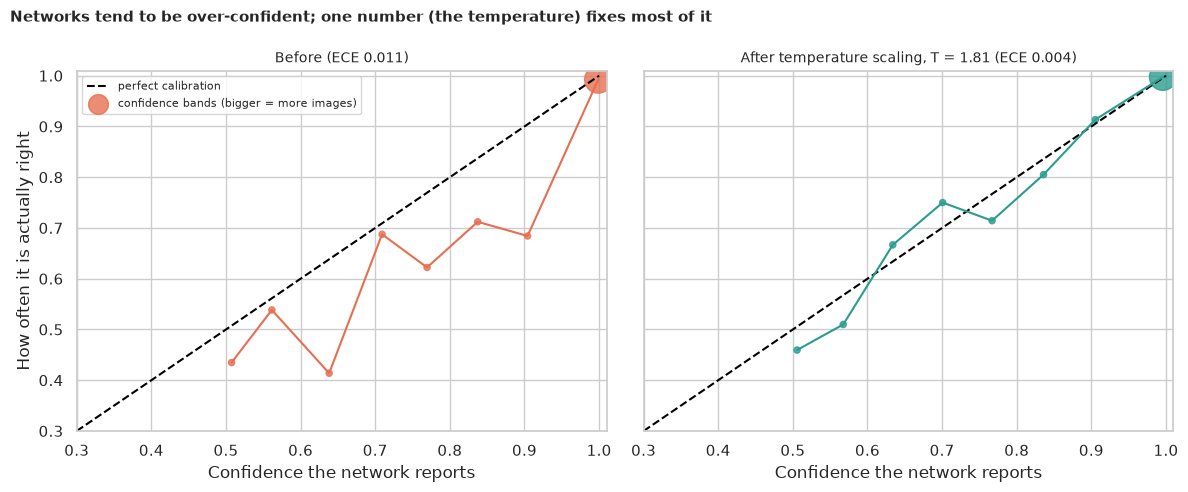

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
edges = np.linspace(0, 1, N_BINS + 1)
for ax, probabilities, title, colour in (
    (axes[0], p_before, f"Before (ECE {ece_before:.3f})", ORANGE),
    (
        axes[1],
        p_after,
        f"After temperature scaling, T = {temperature:.2f} (ECE {ece_after:.3f})",
        TEAL,
    ),
):
    confidence = probabilities.max(axis=1)
    hit = (probabilities.argmax(axis=1) == truth).astype(float)
    bins = np.clip(np.digitize(confidence, edges[1:-1]), 0, N_BINS - 1)
    xs, ys, sizes = [], [], []
    for b in range(N_BINS):
        in_bin = bins == b
        if in_bin.sum() >= 20:
            xs.append(confidence[in_bin].mean())
            ys.append(hit[in_bin].mean())
            sizes.append(in_bin.sum())
    ax.plot([0.3, 1], [0.3, 1], color="black", ls="--", label="perfect calibration")
    ax.scatter(
        xs,
        ys,
        s=np.clip(np.array(sizes) / 25, 20, 400),
        color=colour,
        alpha=0.8,
        label="confidence bands (bigger = more images)",
    )
    ax.plot(xs, ys, color=colour)
    ax.set_xlim(0.3, 1.01)
    ax.set_ylim(0.3, 1.01)
    ax.set_xlabel("Confidence the network reports")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("How often it is actually right")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(
    "Networks tend to be over-confident; one number (the temperature) fixes most of it",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_calibration.png", dpi=150)
plt.show()

**How to read this.**

- **The network is mildly over-confident.** Before scaling, the expected calibration error is **0.0109**: on average its stated confidence is off by about **1.1 percentage points**. The left reliability plot sits slightly *below* the dashed diagonal at high confidence (it says 99% and is right slightly less often). **30 test images were misclassified while the network was more than 99% sure**: the cases where over-confidence bites.
- **Temperature scaling fixes most of it.** The fitted temperature is **T ≈ 1.81** (softening the probabilities), and the ECE falls to **0.0038**, a reduction of **0.0071** (95% bootstrap CI 0.0033 to 0.0092). The CI excludes 0, so **we reject H₀**. The cross-entropy (log loss) also improves from **0.0791 to 0.0628**. The right-hand plot hugs the diagonal.
- **Accuracy is untouched (98.02%):** dividing every score by the same number cannot change which digit wins. We got honest confidence *for free*, with one parameter fitted on held-out data.
- **Why it matters.** An honest "92% sure" lets a cheque-reading system send the doubtful digits to a human and trust the rest. Accuracy alone can't tell you that.

## 11. H6: what if the digits are off-centre?

## 11. H6: what if the digits are off-centre?

*What:* MNIST digits are neatly centred. Real digits from a cheque or a form are not. We take the test images and **slide them sideways by 0 to 6 pixels** (out of 28) and measure the accuracy of an MLP and a small CNN that were both trained **only on centred digits**. *Why:* this is the clearest demonstration of why CNNs exist. An MLP learns "pixel number 400 is ink" for every position separately, so a shifted digit lights up pixels it has never associated with that digit. A CNN's filters look for the same stroke patterns wherever they are. **H₀:** the two models lose the same accuracy under a shift; we test it with McNemar at shifts of 0, 2 and 4 pixels. Three seeds give the spread.

In [13]:
def shift_images(images: torch.Tensor, pixels: int) -> torch.Tensor:
    """Slides every image sideways by a number of pixels, filling the gap with background.

    Args:
        images: Raw images in [0, 1], shape (N, 1, 28, 28).
        pixels: Shift amount (positive = to the right).

    Returns:
        The shifted images.
    """
    if pixels == 0:
        return images
    shifted = torch.zeros_like(images)
    shifted[..., pixels:] = images[..., :-pixels]
    return shifted


SHIFTS = [0, 1, 2, 3, 4, 6]
N_SHIFT_SEEDS = 3
shift_models = {
    kind: [
        train_model(kind, 100 + s, train_std, train_labels, EPOCHS) for s in range(N_SHIFT_SEEDS)
    ]
    for kind in ("mlp", "cnn")
}
shift_acc = {kind: {k: [] for k in SHIFTS} for kind in shift_models}
shift_correct = {}
for k in SHIFTS:
    moved = prepare(shift_images(raw_test, k))
    for kind, models in shift_models.items():
        for seed, model in enumerate(models):
            predictions = predict_logits(model, moved).argmax(1)
            shift_acc[kind][k].append(float((predictions == test_labels).float().mean()))
            if seed == 0:
                shift_correct[(kind, k)] = predictions.cpu().numpy() == truth
shift_table = pd.DataFrame(
    {kind: {k: np.mean(v) for k, v in by_shift.items()} for kind, by_shift in shift_acc.items()}
)
shift_table.index.name = "shift (pixels)"
rng = np.random.default_rng(SEED)
shift_tests = pd.DataFrame(
    {
        f"shift {k} px": mcnemar(shift_correct[("cnn", k)], shift_correct[("mlp", k)], rng)
        for k in (0, 2, 4)
    }
).T
shift_table.rename(columns={"mlp": "MLP", "cnn": "Small CNN"}).style.format("{:.4f}")

,MLP,Small CNN
shift (pixels),,
0,0.9729,0.9875
1,0.9507,0.9838
2,0.8045,0.9655
3,0.5621,0.9036
4,0.3596,0.7395
6,0.1191,0.2994


In [14]:
shift_tests.style.format(
    {
        "accuracy difference": "{:+.4f}",
        "ci_low": "{:+.4f}",
        "ci_high": "{:+.4f}",
        "p": fmt_p,
        "A right, B wrong": "{:.0f}",
        "B right, A wrong": "{:.0f}",
    }
)

,"A right, B wrong","B right, A wrong",accuracy difference,ci_low,ci_high,p
shift 0 px,190,49,+0.0141,+0.0111,+0.0172,8.7e-21
shift 2 px,1556,99,+0.1457,+0.1384,+0.1530,< 1e-300
shift 4 px,3874,267,+0.3607,+0.3502,+0.3711,< 1e-300


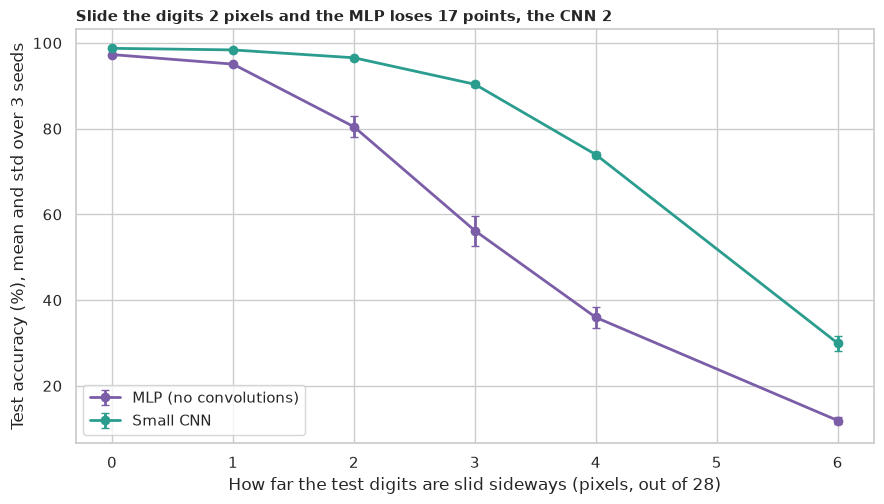

In [15]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for kind, label, colour in (("mlp", "MLP (no convolutions)", PURPLE), ("cnn", "Small CNN", TEAL)):
    means = np.array([np.mean(shift_acc[kind][k]) for k in SHIFTS]) * 100
    spread = np.array([np.std(shift_acc[kind][k], ddof=1) for k in SHIFTS]) * 100
    ax.errorbar(SHIFTS, means, yerr=spread, marker="o", lw=2, capsize=3, color=colour, label=label)
ax.set_xlabel("How far the test digits are slid sideways (pixels, out of 28)")
ax.set_ylabel("Test accuracy (%), mean and std over 3 seeds")
ax.legend(loc="lower left")
drop = {kind: (shift_table[kind].iloc[0] - shift_table.loc[2, kind]) * 100 for kind in shift_table}
ax.set_title(
    f"Slide the digits 2 pixels and the MLP loses {drop['mlp']:.0f} points, the CNN "
    f"{drop['cnn']:.0f}",
    loc="left",
    fontweight="bold",
    fontsize=10.5,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "06_shift_robustness.png", dpi=150)
plt.show()

**How to read this.** (Test accuracy by sideways shift; both models trained only on centred digits.)

| Shift (pixels) | MLP | Small CNN |
|---|---|---|
| 0 | 97.3% | 98.8% |
| 1 | 95.1% | 98.4% |
| 2 | 80.5% | 96.6% |
| 3 | 56.2% | 90.4% |
| 4 | 36.0% | 74.0% |
| 6 | 11.9% | 29.9% |

- **A 2-pixel shift (out of 28) costs the MLP 17 points and the CNN only 2 points.** At 2 pixels the CNN is right and the MLP wrong on 1,556 images, the reverse on only 99 (accuracy difference **+14.6 points**; p far below 1e-300). At 4 pixels the gap is **+36.1 points**. **We reject H₀ at every shift tested**, even at 0 pixels (the CNN is 1.4 points better on centred digits too).
- **The reason is in the analogy.** The MLP has a separate weight for every pixel position; once the digit slides, it lights up pixels the network never associated with that digit. The CNN looks for the same strokes wherever they appear.
- **But the CNN is not magic.** At 4 pixels it has lost a quarter of its accuracy and at 6 pixels it is down to 30%. Convolution gives tolerance to *small* shifts only (and our small CNN has just two pooling steps). Real robustness needs training on shifted examples (augmentation) or a deeper network.

## 12. H7: which digits get confused?

## 12. H7: which digits get confused?

*What:* the final accuracy hides which digits the network finds hard. We take the **small CNN** (first seed) and look at its 10,000 test predictions digit by digit: a **confusion matrix** (rows = the true digit, columns = what the network said), per-digit accuracy with **Wilson 95% confidence intervals**, and a **chi-square test of homogeneity** of the correct/incorrect counts (**H₀:** the network is equally accurate on all ten digits) with **Cramér's V** as the effect size.

In [16]:
best_logits = predict_logits(shift_models["cnn"][0], test_std)
predictions = best_logits.argmax(1).cpu().numpy()
confusion = pd.crosstab(pd.Series(truth, name="true"), pd.Series(predictions, name="predicted"))
per_digit = pd.DataFrame(
    {"correct": np.diag(confusion.to_numpy()), "images": confusion.sum(axis=1).to_numpy()},
    index=range(10),
)
per_digit["accuracy"] = per_digit["correct"] / per_digit["images"]
per_digit["ci_low"], per_digit["ci_high"] = proportion_confint(
    per_digit["correct"], per_digit["images"], method="wilson"
)
chi2, p_digits, dof, _ = stats.chi2_contingency(
    np.column_stack([per_digit["correct"], per_digit["images"] - per_digit["correct"]])
)
cramers_v = float(np.sqrt(chi2 / per_digit["images"].sum()))
off_diagonal = confusion.to_numpy().copy()
np.fill_diagonal(off_diagonal, 0)
top = np.dstack(np.unravel_index(np.argsort(-off_diagonal.ravel())[:5], off_diagonal.shape))[0]
print(f"Small CNN accuracy: {per_digit['correct'].sum() / per_digit['images'].sum():.4f}")
print(
    f"Do digits differ in accuracy? chi2({dof}) = {chi2:.0f}, p = {fmt_p(p_digits)}, "
    f"Cramer's V = {cramers_v:.2f}"
)
print("Five most common mix-ups (true -> predicted: number of test images):")
for true_digit, predicted in top:
    print(f"  {true_digit} read as {predicted}: {off_diagonal[true_digit, predicted]}")
per_digit.sort_values("accuracy").style.format(
    {"accuracy": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}"}
)

Small CNN accuracy: 0.9876
Do digits differ in accuracy? chi2(9) = 49, p = 1.4e-07, Cramer's V = 0.07
Five most common mix-ups (true -> predicted: number of test images):
  9 read as 4: 11
  2 read as 7: 7
  6 read as 5: 7
  3 read as 7: 7
  5 read as 3: 6


,correct,images,accuracy,ci_low,ci_high
9,980,1009,97.13%,95.90%,97.99%
8,957,974,98.25%,97.22%,98.91%
2,1015,1032,98.35%,97.38%,98.97%
3,994,1010,98.42%,97.44%,99.02%
6,945,958,98.64%,97.69%,99.21%
5,880,892,98.65%,97.66%,99.23%
0,971,980,99.08%,98.26%,99.52%
7,1021,1028,99.32%,98.60%,99.67%
4,979,982,99.69%,99.11%,99.90%
1,1134,1135,99.91%,99.50%,99.98%


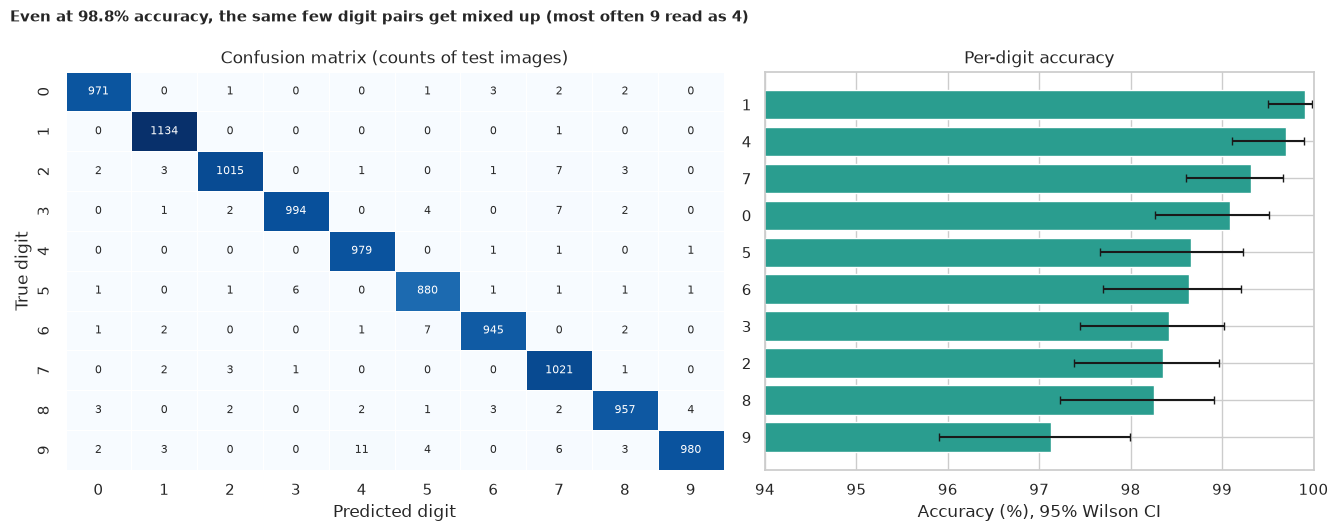

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    linewidths=0.4,
    annot_kws={"fontsize": 8},
)
axes[0].set_xlabel("Predicted digit")
axes[0].set_ylabel("True digit")
axes[0].set_title("Confusion matrix (counts of test images)")
ordered = per_digit.sort_values("accuracy")
ypos = np.arange(len(ordered))
axes[1].barh(
    ypos,
    ordered["accuracy"] * 100,
    color=TEAL,
    xerr=[
        (ordered["accuracy"] - ordered["ci_low"]) * 100,
        (ordered["ci_high"] - ordered["accuracy"]) * 100,
    ],
    capsize=3,
)
axes[1].set_yticks(ypos, [str(d) for d in ordered.index])
axes[1].set_xlim(94, 100)
axes[1].set_xlabel("Accuracy (%), 95% Wilson CI")
axes[1].set_title("Per-digit accuracy")
worst = top[0]
fig.suptitle(
    f"Even at {per_digit['correct'].sum() / 100:.1f}% accuracy, the same few digit pairs "
    f"get mixed up (most often {worst[0]} read as {worst[1]})",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "07_confusion.png", dpi=150)
plt.show()

**How to read this.** The small CNN reaches **98.76%** on this seed, which is about 124 mistakes in 10,000 images.

- **The chi-square test rejects H₀** (χ²(9) ≈ 49, p ≈ 1e-7), so digits differ in difficulty, but the effect is **small** (Cramér's V ≈ 0.07): every digit is above 97%.
- **Easiest: 1 (99.91%), 4 (99.69%) and 7 (99.32%).** A 1 is nearly a straight line and is almost never mistaken for anything.
- **Hardest: 9 (97.13%, CI 95.9% to 98.0%), then 8, 2 and 3.** The CI for 9 does not overlap that of 1 or 4, so that gap is real.
- **The five most common mix-ups are the pairs a person would also find similar:** **9 read as 4 (11 images)**, 2 read as 7, 6 read as 5 and 3 read as 7 (7 each), and 5 read as 3 (6). Many such errors are digits that are sloppily written, or even mislabelled.

## 13. 🎯 Takeaways

1. **Softmax and cross-entropy are a few lines of arithmetic**, and our hand-written versions match PyTorch to 1e-17.
2. **Standardising the inputs is free accuracy:** +0.55 points (CI +0.45 to +0.64), better in 10 of 10 seeds. The legacy notebook skipped it.
3. **Width has diminishing returns:** 10 to 100 hidden units adds 5.4 points; 100 to 1,000 adds only 0.6 for ten times the weights.
4. **Convolutions are about data efficiency.** A CNN with 1,200 images beats an MLP with 6,000, and the CNN's edge shrinks from 6.4 points (300 images) to 1.1 points (60,000).
5. **High accuracy does not mean honest confidence.** The network was over-confident (ECE 0.0109), and one temperature fitted on held-out data cut the error to 0.0038 without changing a single prediction.
6. **MLPs are fragile to off-centre digits:** a 2-pixel shift costs the MLP 17 points and the CNN 2 points; neither survives a 6-pixel shift without augmentation.
7. **The errors are the digits you'd expect:** 9s read as 4s, 2s as 7s.

## 14. ⚠️ Limitations and edge cases

- **MNIST is easy and clean.** Centred, size-normalised digits on a blank background; real handwriting, other scripts and noisy scans are much harder, and a 98.8% score here overstates real-world performance.
- **Small models, short training.** All networks train for 5 to 15 epochs with one optimiser setting and no tuning beyond what's shown; a heavily tuned model gets about 99.7% on MNIST.
- **Five or ten seeds.** Seed spreads are small, but the paired Wilcoxon test with 10 pairs can never beat p = 0.002, and the McNemar tests use one seed's predictions.
- **Calibration is checked on one network.** Temperature scaling is a simple fix that assumes the same T suits all confidence levels; the ECE also depends on how the bins are cut.
- **Shifts are horizontal and wrap-free.** We only slid digits sideways and filled the gap with blank; rotations, scaling and noise would test other kinds of fragility.
- **Test set reuse.** The test set was used to report every comparison (never to choose a setting except where stated), and with many comparisons a little optimism creeps in.

---
*Run `uv run jupyter nbconvert --to html --execute DL/mnist-multiclass/mnist_multiclass.ipynb --output-dir docs --output dl-mnist-multiclass` to rebuild the web version (`docs/dl-mnist-multiclass.html`).*